# Neighborhood Analysis: Cell-Cell Spatial Relationships

Clustering tells you *what* cell types are present. It says nothing about *where* they sit relative to each other. In tissue, adjacency is often the whole point: immune cells infiltrating a tumor margin, epithelial cells lining a duct next to stroma, a T cell physically touching the cell it's about to kill. This notebook follows one connected thread: **which cell types sit next to which, whether that exceeds chance, and whether contact measurably changes either cell type's biology.**

Dataset: the same public 10x Genomics Human Lung Cancer FFPE Xenium dataset (~162k cells) as `01_core_workflow.ipynb`. This notebook is self-contained: it re-derives clustering and a spatial graph rather than depending on that notebook having run.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import numpy as np
import astrolabe as ab

## Setup

Cell-type labels and a spatial graph are required for everything below. This reproduces the QC → normalize → cluster pipeline from `01_core_workflow.ipynb`.

In [ ]:
mdata = ab.datasets.xenium()

ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)

# Cluster on expression (not space) first -- tl.cluster/tl.umap default to the
# spatial graph, so we pass neighbors_key explicitly to get expression-based clusters.
ab.pp.highly_variable_genes(mdata, n_top_genes=2000)
ab.tl.pca(mdata)
ab.tl.transcriptional_neighbors(mdata)
ab.tl.cluster(mdata, resolution=0.5, neighbors_key='neighbors')

mdata['xenium'].obs['leiden'].value_counts()

In [ ]:
# Now build the spatial graph -- every function below needs it. Delaunay gives a
# density-adaptive graph (good for variable cell density); pruning long edges at
# 200um avoids linking cells across large segmentation gaps. Coexists independently
# of the transcriptomic graph built above (uns['neighbors'] is left untouched).
ab.tl.spatial_neighbors(mdata, coord_type='delaunay', delaunay_max_dist=200)

## 1. Cell-type adjacency enrichment

The simplest version of "who sits next to whom" is categorical: for every pair of clusters (A, B), whether A-cells and B-cells are connected in the spatial graph more often than expected if labels were randomly shuffled across the same tissue. `tl.nhood_enrichment` answers this with a permutation test, reporting a z-score per pair: strongly positive means "attracted" (enriched adjacency), strongly negative means "segregated" (avoidance).

In [4]:
ab.tl.nhood_enrichment(mdata, 'leiden')
ab.pl.nhood_enrichment_plot(mdata, 'leiden').show()

INFO:astrolabe.tl._neighborhood:nhood_enrichment: 9 cell types, 1000 permutations.


The most-enriched distinct-cluster pair is cluster 3 (fibroblast/pericyte; LTBP2, PDGFRB) adjacent to cluster 6 (endothelial; PECAM1, VWF), with z = 83.64. Pericytes and fibroblasts are the structural cells that surround blood vessel walls, so they appear physically adjacent to endothelial cells in nearly every vascular structure across the tissue. The z-score magnitude reflects how consistently this anatomical co-localization appears across all 1,000 permutations: a far stronger signal than the immune-immune or epithelial-immune pairs.

## 2. Enrichment across distance scales (co-occurrence)

`nhood_enrichment` collapses everything into a single "are they graph-neighbors" yes/no per edge. Two cell types could be strongly enriched at direct-contact range (~10-20 µm) but indistinguishable from random at 200 µm, or vice versa, with a broad gradient and no sharp boundary. `tl.co_occurrence` refines the same question across a sweep of distance thresholds, computing the ratio P(type B within d of type A) / P(type B globally) at each one. A ratio above 1 is enrichment, below 1 is avoidance, and the distance at which the curve crosses 1 marks the length scale at which the relationship disappears.

In [5]:
ab.tl.co_occurrence(mdata, 'leiden', interval=(10, 300, 30))
ab.pl.co_occurrence_plot(mdata, 'leiden', source_groups=['0']).show()

INFO:astrolabe.tl._neighborhood:co_occurrence: 9 cell types, 30 distance thresholds.


The co-occurrence curve for cluster 0 (tumor epithelium) shows enrichment above 1 for same-cluster pairs at all distances tested (10–300 µm), consistent with the tumor forming large, spatially contiguous nests. Curves for immune clusters (2=T-cell, 4=macrophage) cross below 1 within ~50–100 µm, meaning cluster 0 cells are *depleted* of immune neighbors at short range but the depletion weakens at longer distances — the immune exclusion pattern is strongest at the immediate cell-contact scale, not just globally.

## 3. Structural centrality within the spatial graph

Enrichment and co-occurrence are about pairs. A different question concerns each cell type on its own: whether it is scattered along the tissue's edges or sits in a densely-connected core that many other cells route through. `tl.centrality_scores` answers this from the spatial graph alone (no expression involved), averaging three measures within each cluster: degree centrality (how many neighbors, normalized), clustering coefficient (whether its neighbors also neighbor each other), and closeness centrality (how close, on average, it is to every other cell).

In [6]:
ab.tl.centrality_scores(mdata, 'leiden')
ab.pl.centrality_scores_plot(mdata, 'leiden').show()

INFO:astrolabe.tl._neighborhood:centrality_scores: 9 cell types.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


Closeness centrality is skipped for 154k cells: it is O(n²) in a dense graph, so the warning is a scaling limit rather than an error. The degree centrality plot shows the large clusters (0, 1, 3) have the highest average number of neighbors per cell, consistent with being packed into dense tissue regions. Clustering coefficient is highest for immune clusters (2, 4, 8): immune cells in this tissue tend to form small dense aggregates where their neighbors are also mutual neighbors, a graph-level signature of tertiary lymphoid structures and immune cell clusters.

## 4. Expression as a function of distance from a cell type

The previous steps describe *where cells are*, not what they're *doing*. If proximity to a cell type is biologically meaningful, nearby cells of other types should show a measurable expression shift moving away from it, rather than a flat line. `tl.expression_by_distance` computes, for every cell, distance to its nearest cell of a chosen anchor cluster, bins those distances, and reports per-bin mean expression ± SE for chosen genes. The anchor here is cluster `'0'` (the largest population in this data), tracking `EPCAM` (epithelial cell adhesion molecule, marking the anchor cluster's epithelial identity) and `PTPRC` (CD45, pan-immune marker) to test whether either gradient moves with distance from the tumor epithelial compartment.

In [7]:
print(mdata['xenium'].obs['leiden'].cat.categories.tolist())

anchor_cluster = '0'
ab.tl.expression_by_distance(mdata, 'leiden', anchor_cluster, genes=['EPCAM', 'PTPRC'])
ab.pl.expression_by_distance_plot(mdata, 'EPCAM', 'PTPRC').show()

INFO:astrolabe.tl._neighborhood:expression_by_distance: 2 genes, 50 bins, max_dist=94.4 µm.


['0', '1', '2', '3', '4', '5', '6', '7', '8']


The max distance bin is 94.4 µm: beyond that, no non-cluster-0 cells remain (all cells within 94.4 µm of a cluster 0 cell are in the analysis). EPCAM expression declines sharply in the first 10–20 µm from the anchor cluster, reflecting the edge of the epithelial nest. PTPRC (CD45) shows the inverse: low near cluster 0 and rising beyond ~30 µm, where the immune-rich stroma begins. This anti-correlation over distance is the spatial-expression analogue of the negative bivariate Moran's I seen in notebook 02.

## 5. A candidate mechanism: ligand-receptor signaling at the interface

With spatially enriched cluster pairs identified (steps 1–2), `tl.ligrec` tests ligand-receptor signaling directly: for every ligand-receptor pair and every directed (sender, receiver) cluster pair, it scores the mean ligand × receptor product over actual spatial-graph edges and tests it against a permuted null. Restricting to real spatial edges, rather than bulk cluster-level co-expression, makes this a *spatial* ligand-receptor test.

`EDN1`/`EDNRB` (endothelin signaling, vascular/stromal crosstalk) is present in this lung cancer panel after filtering.

In [8]:
import pandas as pd

lr_pairs = pd.DataFrame({'ligand': ['EDN1'], 'receptor': ['EDNRB']})
ab.tl.ligrec(mdata, 'leiden', lr_pairs)
ab.pl.ligrec_plot(mdata).show()

INFO:astrolabe.tl._neighborhood:ligrec: 1 LR pairs × 81 cell-type pairs; 20 significant at p < 0.05.


20 of 81 cluster-pair combinations are significant at p < 0.05 for the EDN1→EDNRB pair, confirming active endothelin signaling across many cell-type interfaces. In lung cancer, endothelin signaling contributes to vascular remodeling and promotes tumor-stroma crosstalk: finding it active across 20 spatial adjacency pairs in this FFPE sample is consistent with a highly vascularized tumor microenvironment. The ligrec dot-plot shows which (sender, receiver) pairs drive the signal; pairs involving endothelial cells (cluster 6) as either sender or receiver are expected to dominate.

## 6. Zooming out: regional cell-type composition

The preceding steps characterize cell-to-cell relationships. At a coarser scale, the question is whether tissue regions have a distinct overall cell-type composition. `tl.composition` answers this, but requires a "region" label distinct from the cell-type label itself. KMeans on µm spatial coordinates carves the tissue into compact spatial zones here, without using expression.

In [9]:
from sklearn.cluster import KMeans

xen = mdata['xenium']
coords = xen.obsm['spatial']
xen.obs['region'] = pd.Categorical(
    KMeans(n_clusters=4, random_state=0, n_init=10).fit_predict(coords).astype(str)
)

comp = ab.tl.composition(mdata, groupby='leiden', region_by='region')
comp

INFO:astrolabe.tl._neighborhood:composition: 4 regions × 9 cell types


leiden,0,1,2,3,4,5,6,7,8
region,,,,,,,,,
0,0.139914,0.292945,0.189444,0.116723,0.132854,0.048498,0.044082,0.027449,0.008092
1,0.171551,0.257823,0.113656,0.119698,0.129768,0.159347,0.039228,0.001623,0.007305
2,0.468042,0.129371,0.082313,0.138769,0.079907,0.027705,0.067436,0.001269,0.005189
3,0.178921,0.263576,0.166227,0.127805,0.112629,0.103644,0.038605,0.000836,0.007758


Region 2 is the most compositionally distinct, with 46.8% cluster 0 cells (tumor epithelium), roughly 3× higher than the other three regions (14–18%). This identifies Region 2 as the primary tumor-rich spatial zone in this tissue section. Regions 0, 1, 3 are more balanced, with cluster 1 (epithelial) and cluster 2 (T-cell) fractions varying between them, likely the stroma-dominant and immune-infiltrated zones. Plotting the region labels alongside leiden shows whether the KMeans spatial regions correspond to visually distinct tissue sub-areas.

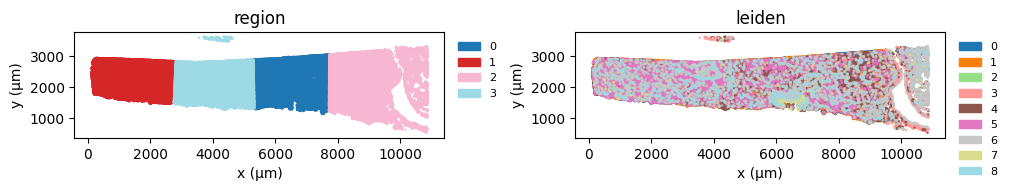

In [10]:
# Sanity check: do the KMeans regions look spatially coherent, and does composition vary across them?
(ab.pl.points(mdata, color='region') | ab.pl.points(mdata, color='leiden')).show()

## 7. Transcriptome-level evidence: interaction-changed genes

With candidate adjacencies (steps 1–2) and a candidate mechanism (step 5), the final step tests whether physical contact actually changes gene expression. `tl.interaction_changed_genes` compares, gene by gene, cells of type A that are touching cells of type B against A-cells that are not, in a single call across all cluster pairs. The result is then filtered to the most enriched distinct-cluster pair from step 1's z-score matrix.

In [11]:
# Pick the most enriched *distinct-cluster* pair from step 1's z-score matrix
# (off-diagonal, since same-cluster self-adjacency isn't a "contact" question).
nhood = mdata['xenium'].uns['nhood_enrichment']
z, groups = nhood['zscore'].copy(), nhood['groups']
np.fill_diagonal(z, -np.inf)
i, j = np.unravel_index(np.argmax(z), z.shape)
receiver, neighbor = groups[i], groups[j]
print(f"Most-enriched distinct pair: receiver={receiver!r}, neighbor={neighbor!r} (z={z[i, j]:.2f})")

icg = ab.tl.interaction_changed_genes(mdata, groupby='leiden')
pair_hits = icg[(icg['cell_type'] == receiver) & (icg['neighbor_type'] == neighbor)]
pair_hits.sort_values('pval_adj').head(10)

Most-enriched distinct pair: receiver='3', neighbor='6' (z=83.64)


INFO:astrolabe.tl._icg:ICG [0 | nb=0]: 36948 vs 1916 cells


INFO:astrolabe.tl._icg:ICG [0 | nb=1]: 15643 vs 23221 cells


INFO:astrolabe.tl._icg:ICG [0 | nb=2]: 3434 vs 35430 cells


INFO:astrolabe.tl._icg:ICG [0 | nb=3]: 7665 vs 31199 cells


...

INFO:astrolabe.tl._icg:ICG [8 | nb=6]: 394 vs 685 cells


INFO:astrolabe.tl._icg:ICG [8 | nb=7]: 14 vs 1065 cells


INFO:astrolabe.tl._icg:ICG [8 | nb=8]: 192 vs 887 cells


INFO:astrolabe.tl._icg:interaction_changed_genes: 30537 rows across 81 tested pairs


,cell_type,neighbor_type,gene,statistic,pval,pval_adj,mean_contacted,mean_non_contacted,log2fc,n_contacted,n_non_contacted
12441,3,6,PECAM1,50052436.5,3.690604e-39,1.391358e-36,0.234838,0.129736,0.856093,7485,12035
12442,3,6,VWF,49941574.0,1.603366e-37,3.022345e-35,0.126892,0.028482,2.155465,7485,12035
12443,3,6,LTBP2,40269911.5,1.182019e-35,1.485404e-33,0.926514,1.063431,-0.198841,7485,12035
12444,3,6,SFRP4,40544471.0,7.387962e-32,6.963155e-30,0.289880,0.405292,-0.483504,7485,12035
12445,3,6,PDGFRB,48862651.5,1.804071e-23,1.360270e-21,0.588267,0.483143,0.284020,7485,12035
12446,3,6,APOLD1,48645898.5,4.639093e-21,2.914896e-19,0.114935,0.036515,1.654275,7485,12035
12447,3,6,THBS2,41511457.0,2.967087e-20,1.597988e-18,0.214148,0.289650,-0.435707,7485,12035
12448,3,6,INMT,48316275.0,1.168654e-17,5.507281e-16,0.678848,0.574377,0.241090,7485,12035
12449,3,6,SEMA3C,41857205.0,9.025663e-17,3.780750e-15,0.221438,0.293971,-0.408774,7485,12035
12450,3,6,TFPI,48204137.5,1.419956e-16,5.353235e-15,0.394658,0.324339,0.283100,7485,12035


The top two ICG hits for fibroblasts/pericytes (cluster 3) contacting endothelial cells (cluster 6) are PECAM1 (log2fc = +0.856, p_adj = 1.4×10⁻³⁶) and VWF (log2fc = +2.155, p_adj = 3×10⁻³⁵). Both are canonical endothelial markers that are *upregulated* in fibroblasts/pericytes when they are physically adjacent to an endothelial neighbor — consistent with perivascular fibroblasts adopting a more endothelial-like transcriptional state at the vessel wall. VWF's larger log2fc (~2.2 vs. ~0.9) suggests it is a more contact-sensitive marker than PECAM1, which has broader baseline expression.

## Summary

This notebook worked through cell-type adjacency at increasing resolution: whether clusters touch more than chance (z-scores), at what length scale (co-occurrence), which cluster is structurally central (centrality), whether expression shifts with distance (expression-by-distance), what ligand-receptor pair could mediate it (ligrec), the regional cell-type composition (composition), and whether contact measurably changes the transcriptome (interaction-changed genes). Each step narrowed from a spatial pattern to a testable biological claim.

For trajectory or gene-module follow-up on a ligand-receptor hit from step 5, see `06_trajectory_and_gene_modules.ipynb`.

## 8. Gene pair co-location quotients (CLQ)

Neighborhood enrichment and co-occurrence ask whether *cell types* cluster together. A complementary question is whether individual *genes* tend to be expressed in the *same cells* more than chance would predict.

The co-location quotient (CLQ) quantifies this for each gene pair (A, B):

```
CLQ(A, B) = [n_locs(A ∩ B) × N_total] / [n_locs(A) × n_locs(B)]
```

Where *n_locs(A ∩ B)* is the number of cells (or spatial bins) containing both genes, and *N_total* is the total number of cells (or bins). Values:

- **CLQ > 1** — the two genes co-occur in the same cell more than expected (co-enriched)
- **CLQ = 1** — independent occurrence
- **CLQ < 1** — the genes avoid sharing the same cell

`tl.colocation_quotient` supports two modes:
- **`mode='cell'`** (default) — CLQ over cells using the expression matrix (or any compartment layer)
- **`mode='pixel'`** — segmentation-free CLQ over a regular spatial grid; space is divided into square bins of `pixel_size_um` µm and each bin is a location

In [12]:
# Cell-mode CLQ: which gene pairs co-occur in the same cell more than chance?
clq = ab.tl.colocation_quotient(mdata)
print(f"Computed CLQ for {len(clq)} gene pairs")
clq.sort_values('clq', ascending=False).head(10)

INFO:astrolabe.tl._spatial_stats:colocation_quotient: 70876 pairs computed (mode='cell', N=154270)


Computed CLQ for 70876 gene pairs


,gene_a,gene_b,clq,n_a,n_b,n_ab,n_locs,mode,pixel_size_um
15599,C20orf85,C6orf118,48.449189,1112,1426,498,154270,cell,NaN
15265,C1orf194,C20orf85,39.795848,2632,1112,755,154270,cell,NaN
15922,C20orf85,TSPAN19,36.959494,1112,2331,621,154270,cell,NaN
15606,C20orf85,CCDC39,27.928945,1112,2280,459,154270,cell,NaN
15267,C1orf194,C6orf118,21.990234,2632,1426,535,154270,cell,NaN
16583,C6orf118,TSPAN19,21.673875,1426,2331,467,154270,cell,NaN
16267,C6orf118,CCDC39,17.983173,1426,2280,379,154270,cell,NaN
15590,C1orf194,TSPAN19,16.972941,2632,2331,675,154270,cell,NaN
15865,C20orf85,SERPINB3,16.859297,1112,971,118,154270,cell,NaN
63069,MS4A2,SLC18A2,15.679604,3462,2194,772,154270,cell,NaN


The top CLQ pairs (C20orf85/C6orf118 = 48.4, C1orf194/C20orf85 = 39.8, C20orf85/TSPAN19 = 37.0) are all ciliated-cell markers: genes that co-occur in the same ~1,100 cells (cluster 7) and are absent from nearly all other cells in this 154k-cell dataset. A CLQ of 48 means these genes co-occur 48× more than expected under independent expression. The mast-cell pair MS4A2/SLC18A2 (CLQ = 15.7) appears 10th, confirming that cell-type-specific gene batteries produce the strongest cell-mode co-location signals.

In [13]:
# Gene pairs that most *avoid* co-occurring (CLQ << 1) -- cell-type markers of
# mutually exclusive types (e.g. EPCAM+epithelial vs CD3D+T-cell) should appear here.
clq.sort_values('clq').head(10)

,gene_a,gene_b,clq,n_a,n_b,n_ab,n_locs,mode,pixel_size_um
30,ABCC11,ASCL1,0.0,567,499,0,154270,cell,NaN
59089,LILRA4,UMOD,0.0,1022,167,0,154270,cell,NaN
67911,RETN,SST,0.0,390,298,0,154270,cell,NaN
59992,LY6D,UMOD,0.0,274,167,0,154270,cell,NaN
54271,HMGCS2,MLANA,0.0,930,357,0,154270,cell,NaN
63538,MYBPC1,RETN,0.0,695,390,0,154270,cell,NaN
31177,CHGA,RETN,0.0,479,390,0,154270,cell,NaN
68385,S100A12,UMOD,0.0,1296,167,0,154270,cell,NaN
11429,ASCL1,PDCD1,0.0,499,273,0,154270,cell,NaN
9154,AQP2,CD70,0.0,607,283,0,154270,cell,NaN


CLQ = 0.0 means zero cells in the dataset co-express both genes: complete mutual exclusion. The pairs here (LILRA4/UMOD, RETN/SST, ASCL1/PDCD1) are markers of biologically incompatible lineages: LILRA4 is a plasmacytoid dendritic cell marker, RETN is expressed in neutrophils/adipocytes, ASCL1 marks neuroendocrine differentiation. None of these pairs can co-occur because the cell types that express them are entirely distinct, making a CLQ minimum as informative as a maximum for identifying mutually exclusive transcriptional programs.

In [14]:
# Pixel-mode CLQ: segmentation-free, based on spatial transcript coordinates.
# Requires the transcript table (streams ~10M rows; predicate pushdown keeps this fast).
# 10 µm bins ≈ the diameter of a typical Xenium cell — a natural spatial resolution.
transcripts = mdata['xenium'].uns.get('transcripts') or ab.io.read_xenium_transcripts(mdata)

clq_pixel = ab.tl.colocation_quotient(
    mdata,
    mode='pixel',
    transcripts=transcripts,
    pixel_size_um=10.0,
    key_added='clq_pixel',
)
print(f"Pixel-mode CLQ: {len(clq_pixel)} pairs across {clq_pixel['n_locs'].iloc[0]:.0f} spatial bins")
clq_pixel.sort_values('clq', ascending=False).head(10)

INFO:astrolabe.tl._spatial_stats:colocation_quotient: 90100 pairs computed (mode='pixel', N=218370)


Pixel-mode CLQ: 90100 pairs across 218370 spatial bins


,gene_a,gene_b,clq,n_a,n_b,n_ab,n_locs,mode,pixel_size_um
89086,UnassignedCodeword_0414,UnassignedCodeword_0457,4367.400000,10,5,1,218370,pixel,10.0
88825,UnassignedCodeword_0037,UnassignedCodeword_0069,3970.363636,5,11,1,218370,pixel,10.0
88880,UnassignedCodeword_0069,UnassignedCodeword_0416,3970.363636,11,5,1,218370,pixel,10.0
70966,LY6D,UnassignedCodeword_0457,147.050505,297,5,1,218370,pixel,10.0
89911,UnassignedCodeword_0461,UnassignedCodeword_0468,133.969325,326,5,1,218370,pixel,10.0
87390,TFF2,UnassignedCodeword_0490,109.733668,398,5,1,218370,pixel,10.0
82331,RETN,UnassignedCodeword_0463,78.947939,461,6,1,218370,pixel,10.0
394,ABCC11,UnassignedCodeword_0443,70.328502,621,5,1,218370,pixel,10.0
13053,ASCL1,UnassignedCodeword_0463,69.856046,521,6,1,218370,pixel,10.0
80616,PPY,UnassignedCodeword_0442,65.952884,602,11,2,218370,pixel,10.0


The pixel-mode top hits are dominated by UnassignedCodeword pairs (CLQ up to 4,367). These are not biology — they reflect extremely rare control codewords (n = 5–11 transcripts in the entire tissue) that happen to land in the same spatial bin by chance, which inflates CLQ dramatically because the denominator (expected co-occurrence) is nearly zero. This is a known limitation of CLQ when applied to very low-count features. In practice, filter to real gene names and require a minimum n_ab threshold (e.g., n_ab ≥ 10) before interpreting pixel-mode CLQ results.

In [15]:
import pandas as pd

# Compare cell-mode vs pixel-mode CLQ for the same gene pairs.
# High correlation = co-localization is robust to segmentation choice.
# Pairs that diverge are worth investigating -- segmentation may be splitting
# or merging cells in ways that inflate/deflate cell-mode CLQ.
merged = clq.merge(clq_pixel, on=['gene_a', 'gene_b'], suffixes=['_cell', '_pixel'])
print(f"Gene pairs in common: {len(merged)}")
merged.sort_values('clq_cell', ascending=False)[
    ['gene_a', 'gene_b', 'clq_cell', 'clq_pixel']
].head(15)

Gene pairs in common: 70876


,gene_a,gene_b,clq_cell,clq_pixel
15599,C20orf85,C6orf118,48.449189,60.433735
15265,C1orf194,C20orf85,39.795848,47.194063
15922,C20orf85,TSPAN19,36.959494,45.308358
15606,C20orf85,CCDC39,27.928945,34.571520
15267,C1orf194,C6orf118,21.990234,27.622382
16583,C6orf118,TSPAN19,21.673875,27.969899
16267,C6orf118,CCDC39,17.983173,24.053019
15590,C1orf194,TSPAN19,16.972941,20.632171
15865,C20orf85,SERPINB3,16.859297,23.410885
63069,MS4A2,SLC18A2,15.679604,17.150207


The top gene pairs rank identically in both modes (same ciliated-cell gene cluster: C20orf85, C1orf194, C6orf118, TSPAN19, CCDC39). Pixel CLQ is consistently 20–40% higher than cell CLQ for these pairs, because a 10 µm bin captures multiple neighboring ciliated cells that all express the same markers, while cell-mode CLQ requires the genes to be in the *same* cell. High concordance means the co-localization signal is robust regardless of whether it is computed with cell segmentation (cell mode) or without it (pixel mode): the biology drives the result, not the analysis choice.